<a href="https://colab.research.google.com/github/24jangdecp-debug/Machine-Learning-Lab-Code-5th-Sem/blob/main/ChaitanyaJ_ml_lab4_C_C4_55.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

# LAB-4: IMPLEMENTATION OF DECISION TREE CLASSIFICATION

# 1. Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# 2. Load the Iris dataset
iris = load_iris()
X = iris.data
y = iris.target

# Convert dataset into a DataFrame
df = pd.DataFrame(X, columns=iris.feature_names)
df["target"] = y
df["species"] = [iris.target_names[i] for i in y]

In [2]:


print("DECISION TREE CLASSIFICATION")
print("=" * 40)

print("\nFirst 5 rows of the dataset:")
print(df.head())

print("\nDataset Shape:", df.shape)
print("\nClass Names:", iris.target_names)
print("\nMissing Values:")
print(df.isnull().sum())

# 3. Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining Samples:", len(X_train))
print("Testing Samples:", len(X_test))

DECISION TREE CLASSIFICATION

First 5 rows of the dataset:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target species  
0       0  setosa  
1       0  setosa  
2       0  setosa  
3       0  setosa  
4       0  setosa  

Dataset Shape: (150, 6)

Class Names: ['setosa' 'versicolor' 'virginica']

Missing Values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
species              0
dtype: int64

Training Samples: 120
Testing Samples: 30



MODEL EVALUATION
Accuracy: 96.67%

Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



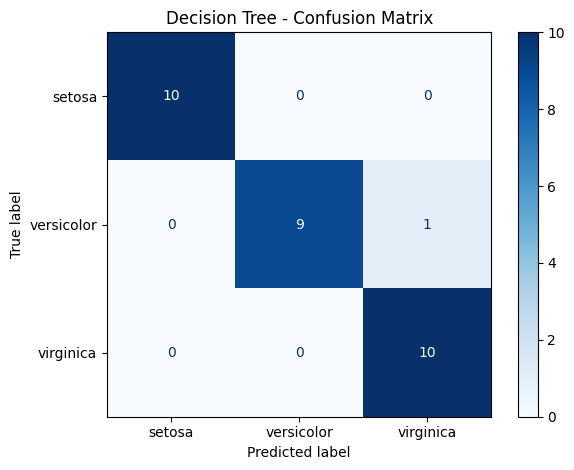

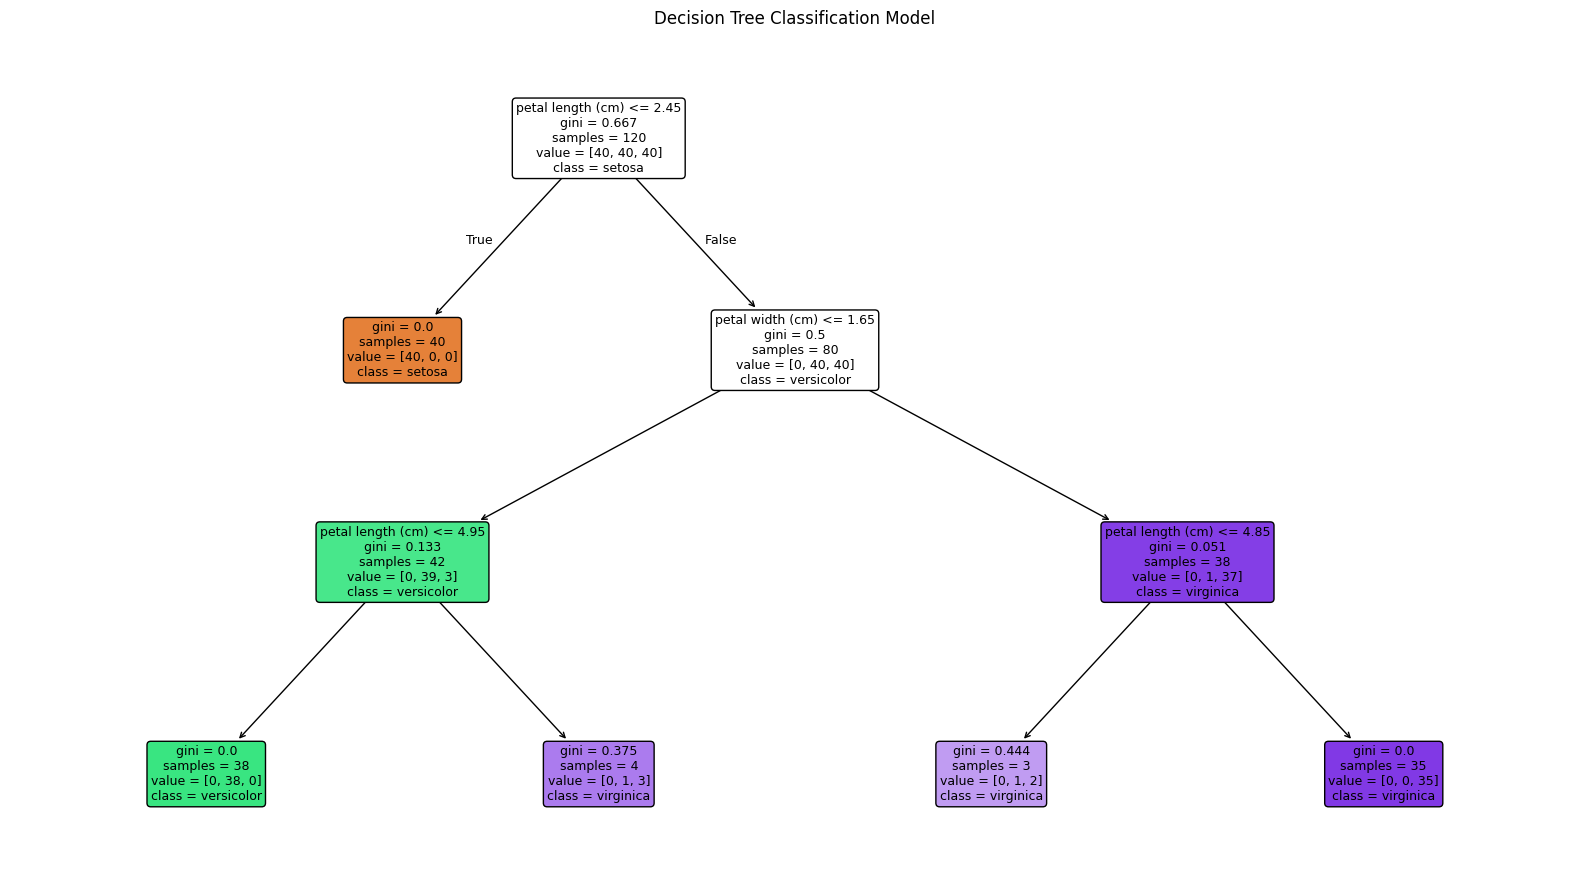


NEW SAMPLE PREDICTION
Input Features: [5.1 3.5 1.4 0.2]
Predicted Species: setosa

Lab-4 execution completed successfully.


In [3]:
# 4. Create and train the Decision Tree model
model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=3,
    random_state=42
)

model.fit(X_train, y_train)

# 5. Make predictions
y_pred = model.predict(X_test)

# 6. Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

print("\nMODEL EVALUATION")
print("=" * 40)
print(f"Accuracy: {accuracy * 100:.2f}%")

print("\nConfusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=iris.target_names,
    zero_division=0
))

# 7. Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=iris.target_names
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Decision Tree - Confusion Matrix")
plt.tight_layout()
plt.show()

# 8. Visualize the Decision Tree
plt.figure(figsize=(16, 9))

plot_tree(
    model,
    feature_names=iris.feature_names,
    class_names=iris.target_names,
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("Decision Tree Classification Model")
plt.tight_layout()
plt.show()

# 9. Predict a new sample
# Features: sepal length, sepal width,
#           petal length, petal width (in cm)
new_sample = np.array([[5.1, 3.5, 1.4, 0.2]])

prediction = model.predict(new_sample)
predicted_species = iris.target_names[prediction[0]]

print("\nNEW SAMPLE PREDICTION")
print("=" * 40)
print("Input Features:", new_sample[0])
print("Predicted Species:", predicted_species)

print("\nLab-4 execution completed successfully.")
